In [1]:
# 0. Setup
from pathlib import Path
import sys

sys.path.insert(0, str(Path.cwd() / 'src'))
from baseline import Workflow
import baseline_report as report

flow = Workflow(Path('config.json'))
flow.start_spark()
report.show_section(flow, '0')


Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/10/22 07:29:11 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Hotels,Folds,PrimaryMetric,CandidateModel,CandidateFeatures,Calibration
"H1, H2",4,LogLoss,rf,f1_17,raw


# Notebook 01 — Baseline

## 1. Problem and evaluation protocol

At T−14 (fourteen days before arrival), predict the probability that a booking will be canceled or become a no-show. The data pipeline fixes this prediction cutoff from EDA. Summing booking probabilities estimates cancellations for overbooking decisions, so probability accuracy matters as well as ranking.

Log loss is the primary metric, with Brier score as a second probability metric. ROC-AUC and Average Precision describe ranking. H1 and H2 are trained and evaluated independently. Select using equal-weight mean log loss across the same four validation cohorts; pooled OOF log loss is supplementary. Calibration uses only the same later folds for every method.


In [2]:
# 2. Load Gold
flow.load()
report.show_section(flow, '2')


Hotel,TotalBookings,DevelopmentBookings,DevelopmentPositives,DevelopmentCancelRate,DevelopmentMinCutoffDate,DevelopmentMaxCutoffDate
H1,20140,16564,1269,0.0766,2015-06-17 00:00:00,2017-04-17 00:00:00
H2,38233,30485,3926,0.1288,2015-06-17 00:00:00,2017-04-17 00:00:00


Hotel,Cohort,Rows,Positives,MinCutoffDate,MaxCutoffDate
H1,Test,3576,withheld,2017-04-18 00:00:00,2017-08-17 00:00:00
H2,Test,7748,withheld,2017-04-18 00:00:00,2017-08-17 00:00:00


## 3. Temporal split and label eligibility

Train on the past and validate on future bookings, using only labels available before each fit date. Split by CutoffDate into four two-month validation windows, fitted on 1 July, 1 September and 1 November 2016, then 1 January 2017, with expanding training history.

A training booking must satisfy CutoffDate < FitDate and LabelAvailableDate < FitDate. For check-outs, label availability is max(ReservationStatusDate, ArrivalDate + TotalNights); for cancellations/no-shows it is ReservationStatusDate. Validation includes every booking in its window. The held-out period is reserved for Notebook 03; here only its row count and CutoffDate bounds are authorized, with positives withheld.


In [3]:
flow.temporal_split()
report.show_section(flow, '3')


97 split, cohort and isolation checks passed


/workspace/Project/Model pipeline/tools/check_legacy_parity.py:26: DtypeWarning: Columns (4) have mixed types. Specify dtype option on import or set low_memory=False.
  table = pd.read_csv(path, dtype={'Booking_ID': str, 'Group': str},


split: historical parity passed; max difference 0.00e+00


97 checks passed (checks are implemented in tests/).


Hotel,Fold,FitDate,TrainRows,TrainLabelsUnavailable,ValidationRows,ValidationPositives
H1,1,2016-07-01 00:00:00,8618,459,1779,115
H1,2,2016-09-01 00:00:00,10353,503,1936,112
H1,3,2016-11-01 00:00:00,12291,501,1152,114
H1,4,2017-01-01 00:00:00,13631,313,1252,119
H2,1,2016-07-01 00:00:00,14230,958,3805,316
H2,2,2016-09-01 00:00:00,17962,1031,3958,534
H2,3,2016-11-01 00:00:00,22069,882,2216,293
H2,4,2017-01-01 00:00:00,24605,562,2359,274


Hotel,Cohort,Rows,Positives,MinCutoffDate,MaxCutoffDate
H1,Development,16564,1269,—,—
H1,Final refit eligible,16019,1250,—,—
H1,Final refit excluded,545,19,—,—
H1,Calibration,6119,460,—,—
H2,Development,30485,3926,—,—
H2,Final refit eligible,29468,3882,—,—
H2,Final refit excluded,1017,44,—,—
H2,Calibration,12338,1417,—,—
H1,Test,3576,withheld,2017-04-18 00:00:00,2017-08-17 00:00:00
H2,Test,7748,withheld,2017-04-18 00:00:00,2017-08-17 00:00:00


**Observation & Decision**

Training expands across folds (H1: 8,618 → 13,631 eligible bookings; H2: 14,230 → 24,605 eligible bookings). Unavailable labels exclude 313–1,031 candidates per window. H1 validation sizes vary from 1,152 to 1,936 bookings; rank candidates by the equal-weight mean of the validation windows.

All later experiments keep these memberships. A known limitation is outcome-dependent selection: cancellations become observable earlier than check-outs. Its effect is examined in Section 5.2; a revised eligibility policy is deferred to Notebook 02.


## 4. Preprocessing

Core 21 contains thirteen numeric, two binary and six categorical inputs from the data pipeline's feature design. Numeric and binary missing values use fitted training medians and modes; categorical missing values use a fixed token. One-hot encoding maps unseen categories to zero blocks. Numeric scaling is enabled only for LR. Each fold fits a fresh preprocessor on its eligible train cohort.

The audit also transforms a validation copy containing deliberate missing values and unseen categories.


In [4]:
flow.preprocess()
report.show_section(flow, '4')


Hotel,Fold,Inputs,OutputColumns,TrainRows,ValidationRows,MatchingColumns,AllFinite
H1,1,21,54,8618,1779,True,True
H1,2,21,54,10353,1936,True,True
H1,3,21,54,12291,1152,True,True
H1,4,21,54,13631,1252,True,True
H2,1,21,53,14230,3805,True,True
H2,2,21,53,17962,3958,True,True
H2,3,21,53,22069,2216,True,True
H2,4,21,53,24605,2359,True,True


Check,Passed
ArrivalDateMonth: unseen category zero block,True
ArrivalDateMonth: fitted missing-token block,True
Meal: unseen category zero block,True
Meal: fitted missing-token block,True
MarketSegment: unseen category zero block,True
MarketSegment: fitted missing-token block,True
DistributionChannel: unseen category zero block,True
DistributionChannel: fitted missing-token block,True
ReservedRoomType: unseen category zero block,True
ReservedRoomType: fitted missing-token block,True


## 5. Baseline: Dummy and LR

### 5.1 Initial fit (Core 21)

Start with a training-prior Dummy and untuned L2 Logistic Regression (C = 1) on Core 21. Can a simple model provide better probabilities than the eligible training cancellation rate? Check the metric functions on known-answer examples, then compare the same validation windows.


In [5]:
flow.initial()
report.show_section(flow, '5.1')


baseline: historical parity passed; max difference 0.00e+00


Hotel,Variant,LogLoss,BrierScore,ROC_AUC,AveragePrecision,PooledOOFLogLoss
H1,Dummy,0.2772,0.0729,0.5000,0.0791,0.2675
H1,LR21,0.5197,0.1742,0.6285,0.1219,0.5486
H2,Dummy,0.3640,0.1039,0.5000,0.1166,0.3613
H2,LR21,0.5683,0.1878,0.5767,0.1400,0.6087


Hotel,Fold,Dummy,LR21
H1,1,0.2420,1.1801
H1,2,0.2246,0.2426
H1,3,0.3260,0.3400
H1,4,0.3161,0.3162
H2,1,0.3085,1.0102
H2,2,0.3957,0.4678
H2,3,0.3907,0.4251
H2,4,0.3610,0.3702


17 known-answer metric checks passed


**Observation & Decision**

| Hotel | Variant | LogLoss | BrierScore | ROC_AUC | AveragePrecision |
| --- | --- | --- | --- | --- | --- |
| H1 | Dummy | 0.2772 | 0.0729 | 0.5000 | 0.0791 |
| H1 | LR21 | 0.5197 | 0.1742 | 0.6285 | 0.1219 |
| H2 | Dummy | 0.3640 | 0.1039 | 0.5000 | 0.1166 |
| H2 | LR21 | 0.5683 | 0.1878 | 0.5767 | 0.1400 |

LR ranks bookings better than Dummy in 8/8 windows, but has worse log loss in 8/8. In H1 fold 1, log loss is 1.1801 versus 0.2420. The ranking signal does not translate into useful probability levels.

**Decision:** diagnose the probability failure before trying another model family.


### 5.2 Diagnosis

Examine three linked explanations: probability levels over time, the arrival-month composition and unavailable labels of the first training cohort, and each feature's contribution to the first-fold LR score. Contribution shifts are validation minus train in log-odds and must reconcile with the actual mean decision-score shift.


In [6]:
flow.diagnose_initial()
report.show_section(flow, '5.2')


Probability rates


Hotel,Variant,Fold,ValidationCancelRate,MeanProbability
H1,Dummy,1,0.0646,0.0834
H1,Dummy,2,0.0579,0.0797
H1,Dummy,3,0.0990,0.0769
H1,Dummy,4,0.0950,0.0774
H1,LR21,1,0.0646,0.6762
H1,LR21,2,0.0579,0.1301
H1,LR21,3,0.0990,0.1709
H1,LR21,4,0.0950,0.1430
H2,Dummy,1,0.0830,0.1535
H2,Dummy,2,0.1349,0.1401


Arrival cohorts


Hotel,ArrivalMonth,EligibleCheckOut,EligiblePositives,UnavailableRows,EligibleRows,EligibleCancelRate
H1,2015-07,846,36,0,882,0.0408
H1,2015-08,821,57,0,878,0.0649
H1,2015-09,875,46,0,921,0.0499
H1,2015-10,700,63,0,763,0.0826
H1,2015-11,433,55,0,488,0.1127
H1,2015-12,489,89,0,578,0.1540
H1,2016-01,168,21,0,189,0.1111
H1,2016-02,395,85,0,480,0.1771
H1,2016-03,738,91,0,829,0.1098
H1,2016-04,859,63,0,922,0.0683


Feature contributions


Hotel,SourceFeature,MeanContributionShift
H1,LeadTime,-0.0667
H1,ArrivalDateYear,2.0434
H1,ArrivalDateWeekNumber,0.5709
H1,ArrivalDateDayOfMonth,-0.0019
H1,StaysInWeekendNights,0.0169
H1,StaysInWeekNights,-0.0210
H1,Adults,-0.0271
H1,Children,0.0392
H1,Babies,-0.0066
H1,ArrivalDayOfWeek,-0.0069


Score reconciliation


Hotel,MeanScoreShift,SumOfFeatureShifts,ReconciliationDifference
H1,3.5372,3.5372,0.0000
H2,2.3853,2.3853,0.0000


Calendar ranges


Hotel,Feature,TrainMin,TrainMax,ValidationMin,ValidationMax,UnseenValidationValues
H1,ArrivalDateYear,2015,2016,2016,2016,0
H1,ArrivalDateWeekNumber,1,53,29,38,0
H2,ArrivalDateYear,2015,2016,2016,2016,0
H2,ArrivalDateWeekNumber,1,53,29,38,0


**Observation & Decision**

H1 fold 1 predicts 67.6% against 6.5% observed; H2 fold 1 predicts 62.3% against 8.3% observed. H2 fold 2 reverses direction (3.9% predicted versus 13.5% observed), so the error is not a fixed offset.

| Hotel | ArrivalMonth | EligibleRows | EligiblePositives | UnavailableRows |
| --- | --- | --- | --- | --- |
| H1 | 2016-07 | 15 | 15 | 295 |
| H2 | 2016-07 | 22 | 22 | 784 |

The newest arrival cohort contains only early observed outcomes; the eligible bookings shown above are all cancellations/no-shows. This is evidence of the eligibility limitation, not evidence about the eventual unavailable labels.

H1's largest upward log-odds shifts are ArrivalDateYear (2.043), ArrivalDateMonth (1.083), ArrivalDateWeekNumber (0.571).

H2's largest upward log-odds shifts are ArrivalDateMonth (1.434), ArrivalDateYear (0.704), ArrivalDateWeekNumber (0.273).

Validation arrival years are already present in train; the evidence is a shift in calendar contributions, not an unseen-year claim.

**Decision:** test whether calendar terms learned a misleading pattern from the selected recent cohort. Remove Year, then Year/Month/Week, while keeping all other settings fixed. This is a hypothesis, not a causal conclusion.


### 5.3 Calendar ablation

Compare LR21, LR20 without Year, and LR18 without Year, Month and Week. Keep eligible training bookings, validation bookings and hyperparameters fixed; change only the declared feature set. Carry the selected calendar-reduced inputs to all later model families.


In [7]:
flow.calendar()
report.show_section(flow, '5.3')


calendar: historical parity passed; max difference 0.00e+00


Hotel,Variant,LogLoss,BrierScore,ROC_AUC,AveragePrecision,PooledOOFLogLoss
H1,Dummy,0.2772,0.0729,0.5000,0.0791,0.2675
H1,LR21,0.5197,0.1742,0.6285,0.1219,0.5486
H1,LR20,0.2741,0.0736,0.6254,0.1208,0.2638
H1,LR18,0.2707,0.0728,0.6331,0.1245,0.2608
H2,Dummy,0.3640,0.1039,0.5000,0.1166,0.3613
H2,LR21,0.5683,0.1878,0.5767,0.1400,0.6087
H2,LR20,0.4085,0.1229,0.5815,0.1437,0.4067
H2,LR18,0.3736,0.1095,0.5931,0.1532,0.3665


Hotel,Fold,Dummy,LR18,LR20,LR21
H1,1,0.2420,0.2381,0.2378,1.1801
H1,2,0.2246,0.2137,0.2176,0.2426
H1,3,0.3260,0.3193,0.3251,0.3400
H1,4,0.3161,0.3119,0.3160,0.3162
H2,1,0.3085,0.3044,0.4130,1.0102
H2,2,0.3957,0.3857,0.3927,0.4678
H2,3,0.3907,0.4287,0.4322,0.4251
H2,4,0.3610,0.3758,0.3961,0.3702


Hotel,Variant,Fold,ValidationCancelRate,MeanProbability
H1,Dummy,1,0.0646,0.0834
H1,Dummy,2,0.0579,0.0797
H1,Dummy,3,0.0990,0.0769
H1,Dummy,4,0.0950,0.0774
H1,LR21,1,0.0646,0.6762
H1,LR21,2,0.0579,0.1301
H1,LR21,3,0.0990,0.1709
H1,LR21,4,0.0950,0.1430
H1,LR20,1,0.0646,0.0595
H1,LR20,2,0.0579,0.0794


**Observation & Decision**

| Hotel | Dummy | LR18 | LR20 | LR21 |
| --- | --- | --- | --- | --- |
| H1 | 0.2772 | 0.2707 | 0.2741 | 0.5197 |
| H2 | 0.3640 | 0.3736 | 0.4085 | 0.5683 |

Removing Year reduces H1 fold-1 log loss from 1.1801 to 0.2378, versus Dummy's 0.2420.

H1: LR18 beats Dummy in folds 1, 2, 3, 4.

H2: LR18 beats Dummy in folds 1, 2.

**Decision:** use the calendar-reduced feature set for all subsequent families, with LR18 as the reference. H2 still needs a more flexible model.


## 6. Model comparison (untuned)

Try nonlinear models on the same eighteen inputs before tuning: RF uses 300 trees, unlimited depth, minimum leaf size 20 and sqrt feature sampling; XGB uses 300 rounds, learning rate 0.05, depth 3, minimum child weight 5 and subsampling 0.8. All remaining settings stay in config.json. Tree models do not scale numeric inputs.

Compare them with Dummy and LR18. The shared runner checks booking, fold, label and date alignment for every variant; the notebook displays that contract once.


In [8]:
flow.untuned()
report.show_section(flow, '6')


untuned: historical parity passed; max difference 1.11e-16


Hotel,Variant,LogLoss,BrierScore,ROC_AUC,AveragePrecision,PooledOOFLogLoss
H1,Dummy,0.2772,0.0729,0.5000,0.0791,0.2675
H1,LR18,0.2707,0.0728,0.6331,0.1245,0.2608
H1,RF18,0.2663,0.0716,0.6574,0.1504,0.2556
H1,XGB18,0.2815,0.0781,0.6466,0.1292,0.2686
H2,Dummy,0.3640,0.1039,0.5000,0.1166,0.3613
H2,LR18,0.3736,0.1095,0.5931,0.1532,0.3665
H2,RF18,0.3670,0.1060,0.5840,0.1708,0.3624
H2,XGB18,0.4021,0.1206,0.5641,0.1583,0.3960


Hotel,Fold,Dummy,LR18,RF18,XGB18
H1,1,0.2420,0.2381,0.2328,0.2389
H1,2,0.2246,0.2137,0.2034,0.2039
H1,3,0.3260,0.3193,0.3133,0.3166
H1,4,0.3161,0.3119,0.3158,0.3668
H2,1,0.3085,0.3044,0.3095,0.3704
H2,2,0.3957,0.3857,0.3863,0.3857
H2,3,0.3907,0.4287,0.3937,0.4306
H2,4,0.3610,0.3758,0.3783,0.4217


Hotel,Variant,Fold,ValidationCancelRate,MeanProbability
H1,Dummy,1,0.0646,0.0834
H1,Dummy,2,0.0579,0.0797
H1,Dummy,3,0.0990,0.0769
H1,Dummy,4,0.0950,0.0774
H1,LR18,1,0.0646,0.0666
H1,LR18,2,0.0579,0.0715
H1,LR18,3,0.0990,0.1345
H1,LR18,4,0.0950,0.1278
H1,RF18,1,0.0646,0.0731
H1,RF18,2,0.0579,0.0712


Hotel,ValidationBookings,VariantsAligned,KeysLabelsFoldsDatesMatch
H1,6119,6,True
H2,12338,6,True


**Observation & Decision**

| Hotel | Dummy | LR18 | RF18 | XGB18 |
| --- | --- | --- | --- | --- |
| H1 | 0.2772 | 0.2707 | 0.2663 | 0.2815 |
| H2 | 0.3640 | 0.3736 | 0.3670 | 0.4021 |

H1: RF18 beats Dummy in 4/4 folds; its mean log loss is 0.2663.

H2: RF18 beats Dummy in 1/4 folds; its mean log loss is 0.3670.

XGB18 H1 fold 4 predicts 17.4% versus 9.5% observed. RF18 overpredicts in 8/8 windows.

**Decision:** useful ranking still does not ensure useful probability levels, especially in H2. Examine overfitting, cancellation-rate drift, probability bias and feature drift before tuning.


## 7. Diagnostics

Why does ranking fail to become better probability accuracy, and why does performance vary by window? Examine four hypotheses on the same LR18/RF18/XGB18 cohorts: overfitting, cancellation-rate drift, probability bias and feature drift.

Compare train and validation loss with the training-prior Dummy on each cohort, reliability within similar-score groups, and distribution changes across every input. Inspect EURUSD, LeadTime and Transient share with group support and cancellation rates. These analyses are descriptive.


Train validation


Hotel,Variant,Fold,TrainLogLoss,LogLoss,DummyTrainLogLoss,DummyLogLoss,GeneralizationGap
H1,LR18,1,0.2606,0.2381,0.2871,0.2420,-0.0225
H1,LR18,2,0.2547,0.2137,0.2780,0.2246,-0.0411
H1,LR18,3,0.2481,0.3193,0.2711,0.3260,0.0712
H1,LR18,4,0.2502,0.3119,0.2724,0.3161,0.0618
H1,RF18,1,0.2150,0.2328,0.2871,0.2420,0.0178
H1,RF18,2,0.2115,0.2034,0.2780,0.2246,-0.0081
H1,RF18,3,0.2054,0.3133,0.2711,0.3260,0.1080
H1,RF18,4,0.2069,0.3158,0.2724,0.3161,0.1089
H1,XGB18,1,0.2136,0.2389,0.2871,0.2420,0.0253
H1,XGB18,2,0.2131,0.2039,0.2780,0.2246,-0.0092


Cancellation rates


Hotel,Fold,TrainRows,ValidationRows,TrainCancelRate,ValidationCancelRate
H1,1,8618,1779,0.0834,0.0646
H1,2,10353,1936,0.0797,0.0579
H1,3,12291,1152,0.0769,0.0990
H1,4,13631,1252,0.0774,0.0950
H2,1,14230,3805,0.1535,0.0830
H2,2,17962,3958,0.1401,0.1349
H2,3,22069,2216,0.1374,0.1322
H2,4,24605,2359,0.1362,0.1162


Probability rates


Hotel,Variant,Fold,ValidationCancelRate,MeanProbability,ProbabilityBias
H1,LR18,1,0.0646,0.0666,0.0020
H1,LR18,2,0.0579,0.0715,0.0136
H1,LR18,3,0.0990,0.1345,0.0355
H1,LR18,4,0.0950,0.1278,0.0328
H1,RF18,1,0.0646,0.0731,0.0085
H1,RF18,2,0.0579,0.0712,0.0134
H1,RF18,3,0.0990,0.1241,0.0251
H1,RF18,4,0.0950,0.1284,0.0334
H1,XGB18,1,0.0646,0.0720,0.0073
H1,XGB18,2,0.0579,0.0638,0.0060


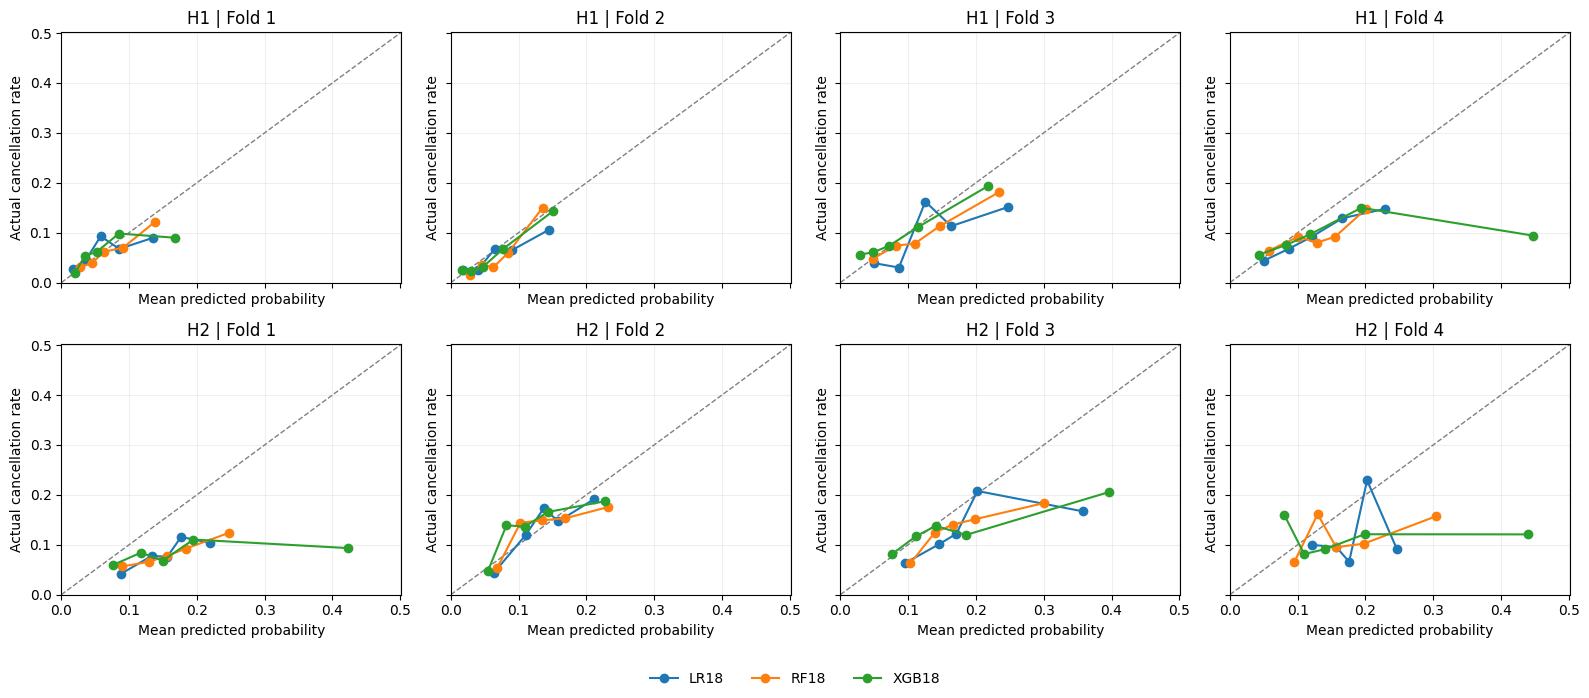

Numeric shift: |validation mean − train mean| / train SD. Categorical shift: total variation.


Numeric distributions


Hotel,Feature,Window,Minimum,Maximum,OutsideInitialRange,Q5,Q25,Q50,Q75,Q95
H1,EURUSD,Initial train,1.0579,1.1569,0.0000,1.0815,1.0973,1.1168,1.1284,1.1419
H1,EURUSD,Fold 1,1.0982,1.1339,0.0000,1.1013,1.1072,1.1135,1.1180,1.1326
H1,EURUSD,Fold 2,1.0872,1.1296,0.0000,1.0886,1.1002,1.1161,1.1220,1.1268
H1,EURUSD,Fold 3,1.0364,1.1095,0.3316,1.0419,1.0548,1.0629,1.0762,1.1093
H1,EURUSD,Fold 4,1.0385,1.0808,0.2125,1.0513,1.0589,1.0632,1.0681,1.0790
H1,LeadTime,Initial train,14.0000,709.0000,0.0000,17.0000,37.0000,78.0000,153.0000,262.0000
H1,LeadTime,Fold 1,14.0000,454.0000,0.0000,17.0000,55.0000,140.0000,201.0000,305.0000
H1,LeadTime,Fold 2,14.0000,542.0000,0.0000,18.0000,41.0000,124.0000,265.0000,386.0000
H1,LeadTime,Fold 3,14.0000,362.0000,0.0000,15.0000,29.0000,58.0000,95.0000,196.0000
H1,LeadTime,Fold 4,14.0000,355.0000,0.0000,16.0000,24.0000,41.0000,96.0000,205.9000


Numeric groups


ValueGroup,Rows,Positives,CancelRate,Share,Hotel,Feature,Window
1,2182,270,0.1237,0.2532,H1,EURUSD,Initial train
2,2241,163,0.0727,0.2600,H1,EURUSD,Initial train
3,2155,130,0.0603,0.2501,H1,EURUSD,Initial train
4,2040,156,0.0765,0.2367,H1,EURUSD,Initial train
1,0,0,—,0.0000,H1,EURUSD,Fold 1
2,1314,77,0.0586,0.7386,H1,EURUSD,Fold 1
3,170,16,0.0941,0.0956,H1,EURUSD,Fold 1
4,295,22,0.0746,0.1658,H1,EURUSD,Fold 1
1,264,10,0.0379,0.1364,H1,EURUSD,Fold 2
2,820,50,0.0610,0.4236,H1,EURUSD,Fold 2


Transient


Hotel,Fold,TrainRows,TrainShare,TrainRate,ValidationRows,ValidationShare,ValidationRate
H1,1,5444,0.6317,0.0861,1425,0.8010,0.0765
H1,2,6867,0.6633,0.0829,1120,0.5785,0.0679
H1,3,7906,0.6432,0.0826,791,0.6866,0.0809
H1,4,8899,0.6529,0.0801,682,0.5447,0.1070
H2,1,6639,0.4665,0.1771,2827,0.7430,0.0937
H2,2,9487,0.5282,0.1532,2888,0.7297,0.1506
H2,3,12305,0.5576,0.1513,1831,0.8263,0.1300
H2,4,14556,0.5916,0.1465,1776,0.7529,0.1070


In [9]:
flow.diagnostics()
report.show_section(flow, '7')


**Observation & Decision**

**Overfitting.** Models improve on Dummy on train in 24/24 fits, but much of the tree models' advantage disappears on validation. XGB18 H1 fold 4 moves from 0.214 train log loss to 0.367 on validation. Complexity needs control.

**Cancellation-rate drift.**

| Hotel | Fold | Train → validation |
| --- | --- | --- |
| H1 | 1 | 8.3% → 6.5% |
| H1 | 2 | 8.0% → 5.8% |
| H1 | 3 | 7.7% → 9.9% |
| H1 | 4 | 7.7% → 9.5% |
| H2 | 1 | 15.4% → 8.3% |
| H2 | 2 | 14.0% → 13.5% |
| H2 | 3 | 13.7% → 13.2% |
| H2 | 4 | 13.6% → 11.6% |

H1 changes direction between the early and later windows; H2 has a large first-window shift. A historical probability level does not match every later cohort.

**Probability bias.** XGB18 H1 fold 4's highest-score group averages 44.8% predicted risk but 9.4% observed cancellations. The reliability curves support trying temporal calibration.

**Feature drift.** In the last validation window, the share in the lowest initial-train EURUSD group is H1 100.0%, H2 100.0%. LeadTime distributions and their within-group cancellation rates also change.

H2's shortest/longest LeadTime groups change from 20.8%/13.4% cancellations in initial train to 11.5%/17.1% in the last window, reversing their risk order.

H2 Transient share is higher in validation than train in 4/4 windows. These are descriptive changes, not causal effects.

**Decision:** tune complexity first, then ablate EURUSD and LeadTime, then calibrate the selected RF. Cancellation-rate drift remains open for Notebook 02.


## 8. Hyperparameter tuning

Test whether controlling complexity improves future probability estimates. Search all three families separately for each hotel on the fixed eighteen inputs and four folds, including their initial configurations. The unchanged grids are LR C in {0.01, 0.1, 1, 10}; RF depth in {6, 12, None} × leaf size in {20, 50, 100}; XGB depth in {2, 3, 4} × minimum child weight in {5, 20} × lambda in {1, 10}. Select by equal-weight mean validation log loss.


In [10]:
flow.tuning()
report.show_section(flow, '8')


H1 lr18_01 {"C": 0.01}


H1 lr18_02 {"C": 0.1}


H1 lr18_03 {"C": 1}


H1 lr18_04 {"C": 10}


H1 rf18_01 {"max_depth": 6, "min_samples_leaf": 20}


H1 rf18_02 {"max_depth": 6, "min_samples_leaf": 50}


... (45 outputs left out)

ModelKey ConfigID                                             GridParameters  LogLoss
      lr  lr18_01                                                {"C": 0.01} 0.365110
      rf  rf18_02                   {"max_depth": 6, "min_samples_leaf": 50} 0.359526
     xgb xgb18_04 {"max_depth": 2, "min_child_weight": 20, "reg_lambda": 10} 0.379862


tuning: historical parity passed; max difference 1.11e-16


Hotel,Variant,LogLoss,BrierScore,ROC_AUC,AveragePrecision,PooledOOFLogLoss,FoldsBeatingDummy,MeanTrainLogLoss,MeanGap,MeanAbsoluteWindowBias,ModelKey,ConfigID,Parameters,InitialLogLoss,InitialGap,DummyLogLoss
H1,LR18 tuned,0.2691,0.0722,0.6445,0.1306,0.2592,4,0.2543,0.0148,0.0222,lr,lr18_02,"{""C"": 0.1}",0.2707,0.0173,0.2772
H1,RF18 tuned,0.2663,0.0716,0.6574,0.1504,0.2556,4,0.2097,0.0567,0.0201,rf,rf18_07,"{""max_depth"": null, ""min_samples_leaf"": 20}",0.2663,0.0567,0.2772
H1,XGB18 tuned,0.2693,0.0728,0.6498,0.1346,0.2586,3,0.2340,0.0353,0.0214,xgb,xgb18_04,"{""max_depth"": 2, ""min_child_weight"": 20, ""reg_lambda"": 10}",0.2815,0.0690,0.2772
H2,LR18 tuned,0.3651,0.1050,0.5855,0.1457,0.3603,2,0.3968,-0.0317,0.0445,lr,lr18_01,"{""C"": 0.01}",0.3736,-0.0197,0.3640
H2,RF18 tuned,0.3595,0.1031,0.6072,0.1768,0.3560,4,0.3658,-0.0063,0.0374,rf,rf18_02,"{""max_depth"": 6, ""min_samples_leaf"": 50}",0.3670,0.0567,0.3640
H2,XGB18 tuned,0.3799,0.1117,0.5791,0.1597,0.3749,1,0.3583,0.0215,0.0500,xgb,xgb18_04,"{""max_depth"": 2, ""min_child_weight"": 20, ""reg_lambda"": 10}",0.4021,0.0742,0.3640


Hotel,Fold,LR18 tuned,RF18 tuned,XGB18 tuned
H1,1,0.2371,0.2328,0.2343
H1,2,0.2122,0.2034,0.2081
H1,3,0.3167,0.3133,0.3184
H1,4,0.3103,0.3158,0.3163
H2,1,0.3046,0.3058,0.3313
H2,2,0.3858,0.3834,0.3902
H2,3,0.3960,0.3879,0.4298
H2,4,0.3740,0.3610,0.3682


**Observation & Decision**

| Hotel | Variant | Parameters | LogLoss | InitialLogLoss | FoldsBeatingDummy |
| --- | --- | --- | --- | --- | --- |
| H1 | LR18 tuned | {"C": 0.1} | 0.2691 | 0.2707 | 4 |
| H1 | RF18 tuned | {"max_depth": null, "min_samples_leaf": 20} | 0.2663 | 0.2663 | 4 |
| H1 | XGB18 tuned | {"max_depth": 2, "min_child_weight": 20, "reg_lambda": 10} | 0.2693 | 0.2815 | 3 |
| H2 | LR18 tuned | {"C": 0.01} | 0.3651 | 0.3736 | 2 |
| H2 | RF18 tuned | {"max_depth": 6, "min_samples_leaf": 50} | 0.3595 | 0.3670 | 4 |
| H2 | XGB18 tuned | {"max_depth": 2, "min_child_weight": 20, "reg_lambda": 10} | 0.3799 | 0.4021 | 1 |

H1's winning RF retains its initial complexity. H2's shallower RF improves mean log loss from 0.3670 to 0.3595, against Dummy's 0.3640, while its mean train/validation gap changes from 0.057 to -0.006.

The two leading H2 RF configurations are nearly tied: {"max_depth": 6, "min_samples_leaf": 50}: 0.359526; {"max_depth": 6, "min_samples_leaf": 100}: 0.359564. The selection rule chooses the lower mean; this small gap is not treated as meaningful evidence.

**Decision:** carry only the separately tuned RF for each hotel into feature ablation. XGB benefits from tuning, but remains behind RF; the H2 LR and XGB means remain behind Dummy.


## 9. Feature ablation (tuned RF)

Do EURUSD and LeadTime, the shifting inputs highlighted above, harm future performance? Keep the tuned per-hotel RF settings and memberships fixed. F0 uses all eighteen inputs; F1 drops EURUSD, F2 drops LeadTime, and F3 drops both. Reuse F0's winning tuning predictions and fit only the declared ablations.


In [11]:
flow.features()
report.show_section(flow, '9')


features: historical parity passed; max difference 1.11e-16


Hotel,Variant,LogLoss,BrierScore,ROC_AUC,AveragePrecision,PooledOOFLogLoss,FoldsBeatingDummy,MeanTrainLogLoss,MeanGap,MeanAbsoluteWindowBias,GainVsF0,FoldsBeatingF0,InputColumns
H1,F0,0.2663,0.0716,0.6574,0.1504,0.2556,4,0.2097,0.0567,0.0201,0.0000,0.0000,18.0000
H1,F1,0.2649,0.0711,0.6576,0.1488,0.2545,4,0.2139,0.0510,0.0090,0.0015,2.0000,17.0000
H1,F2,0.2689,0.0721,0.6356,0.1396,0.2587,3,0.2155,0.0534,0.0207,-0.0026,1.0000,17.0000
H1,F3,0.2693,0.0718,0.6293,0.1353,0.2586,4,0.2210,0.0482,0.0119,-0.0029,1.0000,16.0000
H2,F0,0.3595,0.1031,0.6072,0.1768,0.3560,4,0.3658,-0.0063,0.0374,0.0000,0.0000,18.0000
H2,F1,0.3575,0.1025,0.6127,0.1781,0.3542,4,0.3668,-0.0094,0.0320,0.0021,4.0000,17.0000
H2,F2,0.3605,0.1034,0.6065,0.1721,0.3565,3,0.3696,-0.0092,0.0379,-0.0009,2.0000,17.0000
H2,F3,0.3576,0.1027,0.6118,0.1832,0.3541,4,0.3710,-0.0134,0.0308,0.0019,3.0000,16.0000


Hotel,Variant,Fold,GainVsF0,ValidationCancelRate,MeanProbability,ProbabilityBias
H1,F0,1,0.0000,0.0646,0.0731,0.0085
H1,F0,2,0.0000,0.0579,0.0712,0.0134
H1,F0,3,0.0000,0.0990,0.1241,0.0251
H1,F0,4,0.0000,0.0950,0.1284,0.0334
H1,F1,1,-0.0015,0.0646,0.0762,0.0116
H1,F1,2,0.0000,0.0579,0.0761,0.0183
H1,F1,3,-0.0026,0.0990,0.0973,-0.0016
H1,F1,4,0.0099,0.0950,0.0904,-0.0047
H1,F2,1,-0.0062,0.0646,0.0726,0.0080
H1,F2,2,-0.0029,0.0579,0.0709,0.0130


**Observation & Decision**

| Hotel | F0 | F1 | F2 | F3 |
| --- | --- | --- | --- | --- |
| H1 | 0.2663 | 0.2649 | 0.2689 | 0.2693 |
| H2 | 0.3595 | 0.3575 | 0.3605 | 0.3576 |

H1: F1 improves on F0 in 2/4 windows; mean absolute probability bias falls from 2.0 to 0.9 percentage points.

H2: F1 improves on F0 in 4/4 windows; mean absolute probability bias falls from 3.7 to 3.2 percentage points.

H1's gain is concentrated in the last window; H2 improves consistently. Removing LeadTime alone worsens the mean, so it retains useful signal despite drift. H2 F1 fold 1 still overpredicts by 7.2 percentage points.

**Decision:** select F1 (RF17). EURUSD acts as a time proxy and shifts toward the low end of its training distribution; the log-loss gain supports removing it. RF17 reuses hyperparameters selected on the preceding feature set. Try calibration to address the remaining probability bias.


## 10. Calibration (RF17)

Compare raw, sigmoid and isotonic probabilities for RF17. For fold k, fit a calibrator only on earlier-fold OOF predictions whose labels were available before fold k's fit date, then score fold k. With no earlier OOF for the first fold, evaluate every method on folds 2–4, including a recalculated raw reference. These means must not be compared directly with the earlier four-fold means.


calibration: historical parity passed; max difference 5.18e-15


Hotel,Method,LogLoss,BrierScore,ROC_AUC,AveragePrecision,GainVsRaw,FoldsBeatingRaw,MeanAbsoluteWindowBias,ExactZeroRows,CanceledAtZero
H1,raw,0.2751,0.0748,0.6654,0.1633,0.0000,0,0.0082,0,0
H1,sigmoid,0.2791,0.0757,0.6654,0.1633,-0.0040,0,0.0141,0,0
H1,isotonic,0.3038,0.0757,0.6650,0.1484,-0.0287,0,0.0126,131,3
H2,raw,0.3754,0.1099,0.6116,0.1931,-0.0000,0,0.0187,0,0
H2,sigmoid,0.3782,0.1105,0.6116,0.1931,-0.0028,1,0.0189,0,0
H2,isotonic,0.4059,0.1106,0.6050,0.1723,-0.0305,1,0.0225,388,10


Hotel,Method,Fold,ValidationCancelRate,MeanProbability,LogLoss,GainVsRaw,ExactZeroRows
H1,raw,2,0.0579,0.0761,0.2034,0.0000,0
H1,raw,3,0.0990,0.0973,0.3160,0.0000,0
H1,raw,4,0.0950,0.0904,0.3059,0.0000,0
H1,sigmoid,2,0.0579,0.0797,0.2061,-0.0027,0
H1,sigmoid,3,0.0990,0.0953,0.3234,-0.0074,0
H1,sigmoid,4,0.0950,0.0783,0.3078,-0.0019,0
H1,isotonic,2,0.0579,0.0829,0.2068,-0.0033,50
H1,isotonic,3,0.0990,0.0979,0.3165,-0.0005,30
H1,isotonic,4,0.0950,0.0833,0.3881,-0.0823,51
H2,raw,2,0.1349,0.1386,0.3832,-0.0000,0


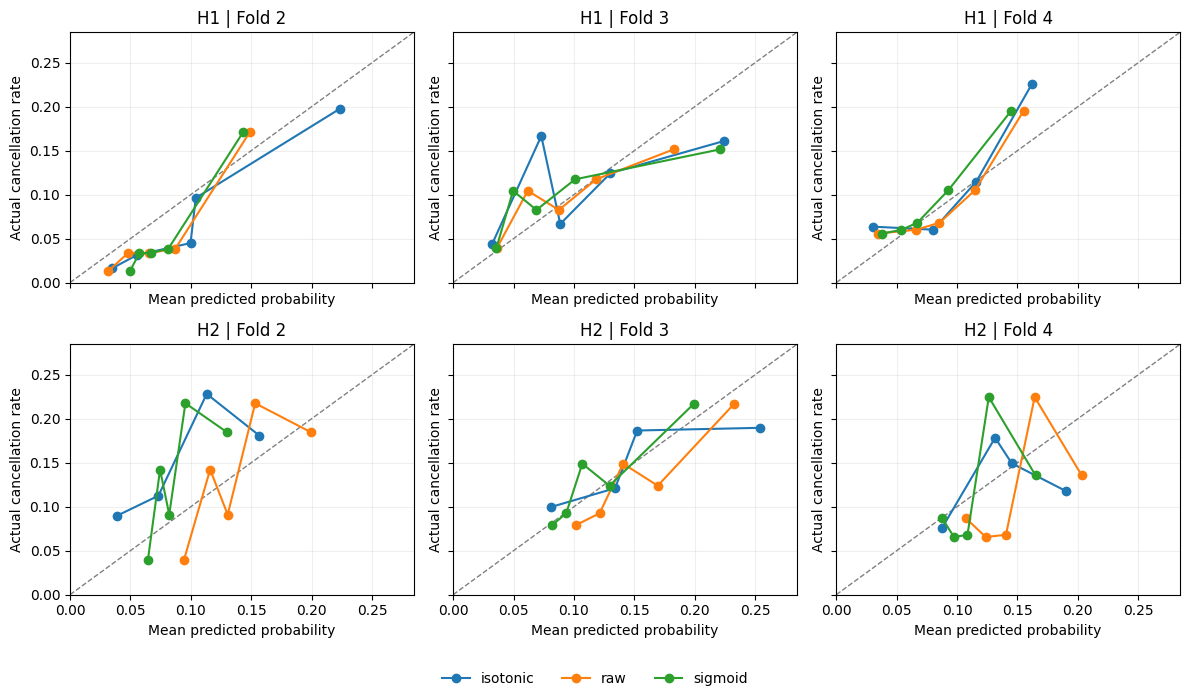

In [12]:
flow.calibrate()
report.show_section(flow, '10')


**Observation & Decision**

| Hotel | Method | LogLoss | BrierScore | FoldsBeatingRaw | ExactZeroRows | CanceledAtZero |
| --- | --- | --- | --- | --- | --- | --- |
| H1 | raw | 0.2751 | 0.0748 | 0 | 0 | 0 |
| H1 | sigmoid | 0.2791 | 0.0757 | 0 | 0 | 0 |
| H1 | isotonic | 0.3038 | 0.0757 | 0 | 131 | 3 |
| H2 | raw | 0.3754 | 0.1099 | 0 | 0 | 0 |
| H2 | sigmoid | 0.3782 | 0.1105 | 1 | 0 | 0 |
| H2 | isotonic | 0.4059 | 0.1106 | 1 | 388 | 10 |

Raw has the best mean log loss and Brier score for both hotels on the same later validation folds. In H2 fold 2, actual cancellations are 13.5%; raw predicts 13.9%, sigmoid predicts 8.9%, isotonic predicts 8.2%. The calibrators learn from an earlier period and adjust toward a probability level that is no longer representative.

Isotonic assigns zero probability to 131 bookings in H1, including 3 cancellations; 388 bookings in H2, including 10 cancellations, causing large log-loss penalties.

**Decision:** retain raw probabilities. A mapping learned from earlier OOF periods does not resolve the changing probability bias; this remains open for Notebook 02.


## 11. Frozen baseline

Summarize the selected development candidate and its limitations for Notebook 02. Compare Dummy with RF17 raw on the same validation bookings. Inspect CustomerType, fixed LeadTime groups and MarketSegment with at least thirty bookings, ranked by their contribution to log loss above Dummy.

Run the refit code only in rehearsal mode on validation fold 4, verify its CV metrics, and save the baseline configuration, fold metrics and OOF predictions. This stage has no held-out input or held-out scoring path.


In [13]:
flow.freeze()
report.show_section(flow, '11')


H1: 6,119 bookings | LeadTime edges [37.0, 78.0, 153.0] | 612 high-loss bookings


H1: fold 4 rehearsal max difference 5.6e-17


H2: 12,338 bookings | LeadTime edges [34.0, 65.0, 112.0] | 1,249 high-loss bookings


H2: fold 4 rehearsal max difference 0.0e+00


frozen: historical parity passed; max difference 7.11e-15


Hotel,Variant,LogLoss,BrierScore,ROC_AUC,AveragePrecision
H1,Dummy,0.2772,0.0729,0.5000,0.0791
H1,F1,0.2649,0.0711,0.6576,0.1488
H2,Dummy,0.3640,0.1039,0.5000,0.1166
H2,F1,0.3575,0.1025,0.6127,0.1781


Hotel,Fold,Dummy,F1
H1,1,0.2420,0.2342
H1,2,0.2246,0.2034
H1,3,0.3260,0.3160
H1,4,0.3161,0.3059
H2,1,0.3085,0.3038
H2,2,0.3957,0.3832
H2,3,0.3907,0.3863
H2,4,0.3610,0.3567


Hotel,Fold,Dimension,Group,Rows,Positives,MeanProbability,LogLoss,DummyLogLoss,TotalLoss,TotalExcessLoss,CancelRate,ProbabilityBias,ExcessLogLoss,Rows_window,CVExcessContribution
H2,3,LeadTime,G4,495,39,0.1547,0.3290,0.2925,162.8350,18.0299,0.0788,0.0759,0.0364,2216,0.0081
H2,3,MarketSegment,Groups,246,50,0.2219,0.5512,0.5212,135.5907,7.3764,0.2033,0.0187,0.0300,2216,0.0033
H1,4,LeadTime,G3,293,15,0.0693,0.2199,0.2074,64.4251,3.6483,0.0512,0.0182,0.0125,1252,0.0029
H2,4,LeadTime,G1,949,109,0.1715,0.3631,0.3586,344.6237,4.3385,0.1149,0.0566,0.0046,2359,0.0018
H1,3,LeadTime,G4,112,14,0.0694,0.4057,0.3907,45.4367,1.6804,0.1250,-0.0556,0.0150,1152,0.0015
H2,2,MarketSegment,Direct,252,25,0.1487,0.3493,0.3310,88.0333,4.6326,0.0992,0.0495,0.0184,3958,0.0012
H2,1,MarketSegment,Direct,320,24,0.1650,0.3063,0.2947,98.0233,3.7096,0.0750,0.0900,0.0116,3805,0.0010
H1,1,MarketSegment,Online TA,858,59,0.0952,0.2539,0.2519,217.8151,1.6676,0.0688,0.0265,0.0019,1779,0.0009
H2,4,MarketSegment,Corporate,39,2,0.1859,0.2971,0.2411,11.5858,2.1826,0.0513,0.1346,0.0560,2359,0.0009
H1,2,MarketSegment,Corporate,44,2,0.1044,0.2096,0.1943,9.2212,0.6742,0.0455,0.0589,0.0153,1936,0.0003


Hotel,Fold,Metric,MaxAbsDifference
H1,4,LogLoss,0.0000
H1,4,BrierScore,0.0000
H1,4,ROC_AUC,0.0000
H1,4,AveragePrecision,0.0000
H2,4,LogLoss,0.0000
H2,4,BrierScore,0.0000
H2,4,ROC_AUC,0.0000
H2,4,AveragePrecision,0.0000


**Observation & Decision**

| Hotel | Variant | Parameters | LogLoss | BrierScore | ROC_AUC | AveragePrecision |
| --- | --- | --- | --- | --- | --- | --- |
| H1 | Dummy | — | 0.2772 | 0.0729 | 0.5000 | 0.0791 |
| H1 | RF17 raw | {"max_depth": null, "min_samples_leaf": 20} | 0.2649 | 0.0711 | 0.6576 | 0.1488 |
| H2 | Dummy | — | 0.3640 | 0.1039 | 0.5000 | 0.1166 |
| H2 | RF17 raw | {"max_depth": 6, "min_samples_leaf": 50} | 0.3575 | 0.1025 | 0.6127 | 0.1781 |

RF17 beats Dummy in 4/4 windows for H1; 4/4 windows for H2, but the mean gains remain modest, especially in H2.

The largest supported excess-loss contribution is H2 fold 3, LeadTime=G4: 7.9% observed versus 15.5% predicted. These segment results are diagnostic, not a new selection exercise.

The last-validation-fold refit rehearsal reproduces CV metrics with maximum absolute difference 5.55e-17.

**Decision:** freeze RF17 raw as the development baseline for Notebook 02, using the selected per-hotel settings shown in Section 8. No held-out outcomes or predictions enter this decision.

**Known limitations:** eligibility depends on observed outcome; cancellation-rate and feature drift remain unresolved; daily aggregate cancellation error and the information ceiling have not been measured. Repeated choices on the same validation folds make CV somewhat optimistic. Independent held-out evaluation belongs to Notebook 03.


### Historical replay comparison

The checker compares the current development run with the frozen historical CV references without modifying them. Every stage stops if a metric differs by more than 1e-4 or cohort keys, labels or dates differ. The table below is read from this run's outputs; no held-out reference is used.


In [14]:
report.show_parity(flow)


Development replay only. Each maximum is taken over matching folds/bookings; tolerance = 1e-4.
The displayed means use the named metric; the maximum covers every metric in that check. Detailed values: outputs/baseline01/parity/comparison.csv.


Stage,Check,DisplayedMetric,RerunMean,HistoricalMean,MetricsCompared,MaxAbsDifference,Pass
split,H1 cv_membership,Membership,—,—,1,0.00e+00,True
split,H1 fit_eligibility,Membership,—,—,1,0.00e+00,True
split,H1 refit_membership,Membership,—,—,1,0.00e+00,True
split,H1 calibration_membership,Membership,—,—,1,0.00e+00,True
split,H2 cv_membership,Membership,—,—,1,0.00e+00,True
split,H2 fit_eligibility,Membership,—,—,1,0.00e+00,True
split,H2 refit_membership,Membership,—,—,1,0.00e+00,True
split,H2 calibration_membership,Membership,—,—,1,0.00e+00,True
baseline,H1 Dummy,LogLoss,0.27717213,0.27717213,4,0.00e+00,True
baseline,H1 Dummy OOF,RawProbability,0.07977929,0.07977929,1,0.00e+00,True
